# Preprocessing Validation
This notebook inspects the processed CSV files (`train.csv`, `val.csv`, `test.csv`) and verifies that they are correctly generated for the HARN architecture. It also uses raw CSVs and pickle statistics where necessary.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import pickle
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_style('whitegrid')

In [4]:
# Paths
ROOT = Path.cwd().parent  # adjust if running inside notebooks/
RAW_DIR = ROOT / 'data' / 'raw'
PROC_DIR = ROOT / 'data' / 'processed'
assert RAW_DIR.exists(), f'Raw data directory not found at {RAW_DIR}'
assert PROC_DIR.exists(), f'Processed directory not found at {PROC_DIR}'

## 1. Load Raw Data

In [5]:
raw_m15 = pd.read_csv(RAW_DIR / 'EURUSD_M15.csv', header=None,
                      names=['datetime','open','high','low','close','volume'])
raw_h1  = pd.read_csv(RAW_DIR / 'EURUSD_H1.csv', header=None,
                      names=['datetime','open','high','low','close','volume'])
raw_h4  = pd.read_csv(RAW_DIR / 'EURUSD_H4.csv', header=None,
                      names=['datetime','open','high','low','close','volume'])
for name, df in [('M15', raw_m15), ('H1', raw_h1), ('H4', raw_h4)]:
    print(f'{name}: {df.shape[0]} rows, memory {df.memory_usage(deep=True).sum()/1e6:.2f} MB')
    df['datetime'] = pd.to_datetime(df['datetime'])
    df.sort_values('datetime', inplace=True)

M15: 100000 rows, memory 11.30 MB
H1: 100000 rows, memory 11.30 MB
H4: 25850 rows, memory 2.92 MB


## 2. Load Processed CSV Files

In [6]:
train = pd.read_csv(PROC_DIR / 'train.csv')
val   = pd.read_csv(PROC_DIR / 'val.csv')
test  = pd.read_csv(PROC_DIR / 'test.csv')
for name, df in [('train', train), ('val', val), ('test', test)]:
    print(f'{name}: {df.shape[0]} samples, {df.shape[1]} columns, memory {df.memory_usage(deep=True).sum()/1e6:.2f} MB')

train: 69967 samples, 289 columns, memory 179.82 MB
val: 14992 samples, 289 columns, memory 38.53 MB
test: 14994 samples, 289 columns, memory 38.53 MB


## 3. Chronological Order & Split Boundaries

In [7]:
# Ensure anchor_time is datetime and sorted
for df in [train, val, test]:
    df['anchor_time'] = pd.to_datetime(df['anchor_time'])
    assert df['anchor_time'].is_monotonic_increasing, 'Not sorted'

# Boundary checks
train_end = train['anchor_time'].iloc[-1]
val_start = val['anchor_time'].iloc[0]
val_end   = val['anchor_time'].iloc[-1]
test_start = test['anchor_time'].iloc[0]
assert train_end < val_start, f'Train/val overlap: {train_end} -> {val_start}'
assert val_end < test_start, f'Val/test overlap: {val_end} -> {test_start}'
print('Chronological split confirmed.')
print(f'Train: {train["anchor_time"].min()}  ->  {train["anchor_time"].max()}')
print(f'Val:   {val["anchor_time"].min()}    ->  {val["anchor_time"].max()}')
print(f'Test:  {test["anchor_time"].min()}   ->  {test["anchor_time"].max()}')

Chronological split confirmed.
Train: 2022-07-26 03:45:00  ->  2025-05-15 08:00:00
Val:   2025-05-15 08:15:00    ->  2025-12-19 13:00:00
Test:  2025-12-19 13:15:00   ->  2026-07-29 07:45:00


## 4. Data Integrity Assertions (NaNs, duplicates, columns)

In [8]:
# No NaNs anywhere
assert not train.isnull().any().any(), 'Train contains NaNs'
assert not val.isnull().any().any()
assert not test.isnull().any().any()
# No duplicate anchor_time within a split
assert train['anchor_time'].duplicated().sum() == 0
assert val['anchor_time'].duplicated().sum() == 0
assert test['anchor_time'].duplicated().sum() == 0
# Column count must be: M15 32*5=160, H1 16*5=80, H4 8*5=40 + 9 metadata = 289
expected_cols = 160 + 80 + 40 + 9
for df in [train, val, test]:
    assert df.shape[1] == expected_cols, f'Expected {expected_cols} columns, got {df.shape[1]}'
# Check that each window has correct temporal offsets
m15_offsets = [int(c.split('_t')[1]) for c in train.columns if c.startswith('m15_')]
assert min(m15_offsets) == -31 and max(m15_offsets) == 0
h1_offsets = [int(c.split('_t')[1]) for c in train.columns if c.startswith('h1_')]
assert min(h1_offsets) == -15 and max(h1_offsets) == 0
h4_offsets = [int(c.split('_t')[1]) for c in train.columns if c.startswith('h4_')]
assert min(h4_offsets) == -7 and max(h4_offsets) == 0
print('Integrity checks passed.')

Integrity checks passed.


## 5. Reconstruct One HTSN Sample

In [9]:
sample = train.iloc[0]
print(f'Anchor: {sample["anchor_time"]}')
# Reshape flat features to (window, features)
def extract_window(row, prefix, window_len, n_features=5):
    cols = [f'{prefix}_{f}_t{off}' for off in range(-window_len+1, 1) for f in ['open','high','low','close','volume']]
    return row[cols].values.reshape(window_len, n_features)

m15_win = extract_window(sample, 'm15', 32)
h1_win  = extract_window(sample, 'h1', 16)
h4_win  = extract_window(sample, 'h4', 8)
print(f'M15 window shape: {m15_win.shape}, H1: {h1_win.shape}, H4: {h4_win.shape}')
# Show as DataFrames
cols = ['open','high','low','close','volume']
display(pd.DataFrame(m15_win, columns=cols).head(10))
display(pd.DataFrame(h1_win, columns=cols).head(5))
display(pd.DataFrame(h4_win, columns=cols))

Anchor: 2022-07-26 03:45:00
M15 window shape: (32, 5), H1: (16, 5), H4: (8, 5)


,open,high,low,close,volume
0,-1.398259,-1.409799,-1.396205,-1.3983,-0.548594
1,-1.377621,-1.389724,-1.392965,-1.398004,-0.643639
2,-1.374377,-1.385592,-1.368824,-1.377661,-0.815238
3,-1.373495,-1.372894,-1.364113,-1.374712,-0.576816
4,-1.368187,-1.3664,-1.362934,-1.373535,-0.225508
5,-1.378507,-1.378504,-1.368234,-1.368523,-0.299792
6,-1.369955,-1.382048,-1.369413,-1.378251,-0.645261
7,-1.366121,-1.37762,-1.366763,-1.369995,-0.132409
8,-1.347254,-1.359315,-1.357634,-1.367046,0.038217
9,-1.360227,-1.351344,-1.349094,-1.347293,-0.19534


,open,high,low,close,volume
0,-1.372369,-1.385115,-1.382665,-1.397364,-0.690629
1,-1.364996,-1.378612,-1.355912,-1.372601,-0.348173
2,-1.397131,-1.363533,-1.380902,-1.366113,0.122595
3,-1.418063,-1.414091,-1.39678,-1.397659,-0.198707
4,-1.426613,-1.440702,-1.413243,-1.418297,-0.763195


,open,high,low,close,volume
0,-1.417042,-1.388344,-1.370572,-1.397166,-0.273849
1,-1.408783,-1.45775,-1.391098,-1.41811,-0.882421
2,-1.455087,-1.450929,-1.416903,-1.410736,-0.540405
3,-1.397282,-1.373511,-1.42511,-1.456751,0.226739
4,-1.505817,-1.365208,-1.497833,-1.398639,0.783244
5,-1.463936,-1.470504,-1.474961,-1.506899,0.430306
6,-1.48694,-1.498388,-1.490503,-1.465012,0.170047
7,-1.4601,-1.481776,-1.437722,-1.488315,-0.851254


## 6. Multi‑Timeframe Alignment Verification

In [10]:
def check_alignment(sample, raw_m15, raw_h1, raw_h4):
    anchor = pd.Timestamp(sample['anchor_time'])
    # M15 window should end at anchor
    m15_anch_idx = raw_m15[raw_m15['datetime'] == anchor].index
    assert len(m15_anch_idx) == 1, f'M15 anchor {anchor} not found'
    m15_start_idx = m15_anch_idx[0] - 31
    assert m15_start_idx >= 0
    # H1: latest completed H1 bar ≤ anchor
    h1_completed = raw_h1[raw_h1['datetime'] <= anchor]
    h1_latest = h1_completed['datetime'].max()
    h1_win_start = h1_completed.iloc[-16]['datetime']
    # H4 similarly
    h4_completed = raw_h4[raw_h4['datetime'] <= anchor]
    h4_latest = h4_completed['datetime'].max()
    h4_win_start = h4_completed.iloc[-8]['datetime']
    print(f'Anchor: {anchor}')
    print(f'  M15 window: {raw_m15.loc[m15_start_idx,"datetime"]} -> {anchor}')
    print(f'  H1 window: {h1_win_start} -> {h1_latest}')
    print(f'  H4 window: {h4_win_start} -> {h4_latest}')

for i in [0, 100, 500]:  # random indices
    print(f'--- Sample {i} ---')
    check_alignment(train.iloc[i], raw_m15, raw_h1, raw_h4)

--- Sample 0 ---
Anchor: 2022-07-26 03:45:00
  M15 window: 2022-07-25 20:00:00 -> 2022-07-26 03:45:00
  H1 window: 2022-07-25 12:00:00 -> 2022-07-26 03:00:00
  H4 window: 2022-07-24 20:00:00 -> 2022-07-26 00:00:00
--- Sample 100 ---
Anchor: 2022-07-27 04:45:00
  M15 window: 2022-07-26 21:00:00 -> 2022-07-27 04:45:00
  H1 window: 2022-07-26 13:00:00 -> 2022-07-27 04:00:00
  H4 window: 2022-07-26 00:00:00 -> 2022-07-27 04:00:00
--- Sample 500 ---
Anchor: 2022-08-02 08:45:00
  M15 window: 2022-08-02 01:00:00 -> 2022-08-02 08:45:00
  H1 window: 2022-08-01 17:00:00 -> 2022-08-02 08:00:00
  H4 window: 2022-08-01 04:00:00 -> 2022-08-02 08:00:00


## 7. Event Flags: `is_h1_update` & `is_h4_update`

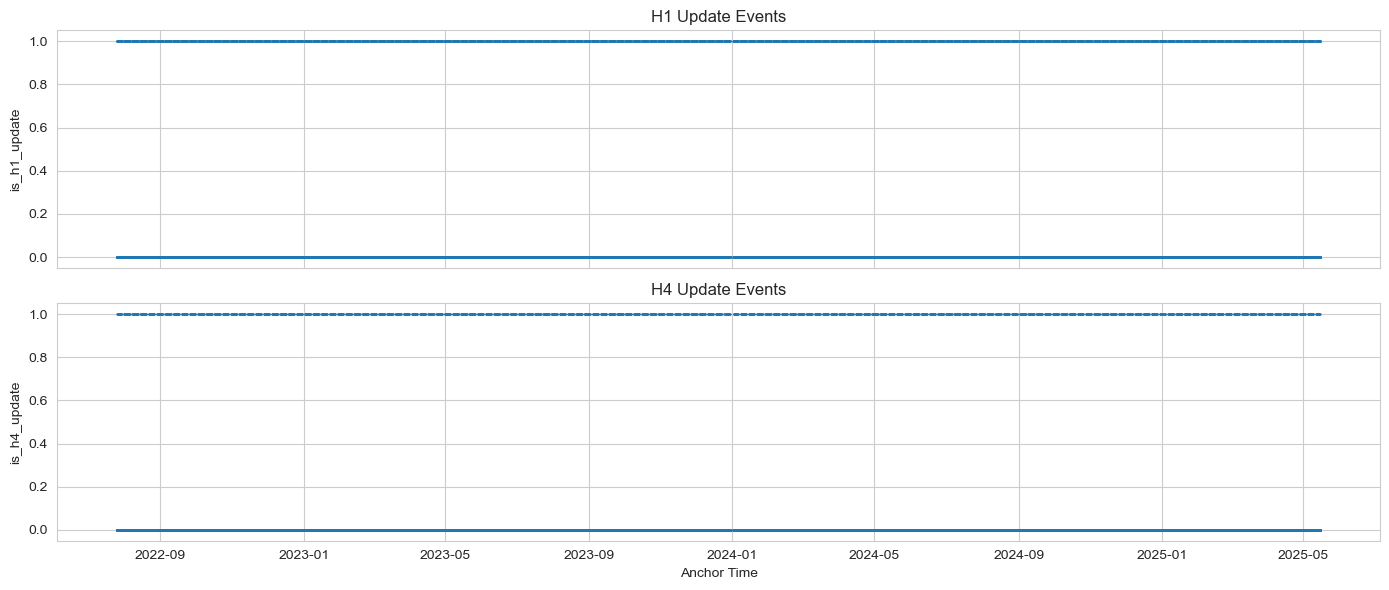

H1 updates: 17494
H4 updates: 4374
H1 flag accuracy: 100.00%
H4 flag accuracy: 100.00%

✓ H1 and H4 update flags verified successfully.


In [11]:
# ---------------------------------------------------------
# Visualize update flags
# ---------------------------------------------------------
train["anchor_time"] = pd.to_datetime(train["anchor_time"])

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(
    train["anchor_time"],
    train["is_h1_update"],
    marker=".",
    linestyle="None",
    ms=1
)
axes[0].set_ylabel("is_h1_update")
axes[0].set_title("H1 Update Events")

axes[1].plot(
    train["anchor_time"],
    train["is_h4_update"],
    marker=".",
    linestyle="None",
    ms=1
)
axes[1].set_ylabel("is_h4_update")
axes[1].set_title("H4 Update Events")

plt.xlabel("Anchor Time")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Verify update flags using timestamps
# ---------------------------------------------------------

expected_h1 = (
    train["anchor_time"].dt.minute == 0
).astype(int)

expected_h4 = (
    (train["anchor_time"].dt.minute == 0) &
    (train["anchor_time"].dt.hour % 4 == 0)
).astype(int)

h1_correct = (train["is_h1_update"] == expected_h1).all()
h4_correct = (train["is_h4_update"] == expected_h4).all()

print(f"H1 updates: {train['is_h1_update'].sum()}")
print(f"H4 updates: {train['is_h4_update'].sum()}")

print(f"H1 flag accuracy: {(train['is_h1_update'] == expected_h1).mean()*100:.2f}%")
print(f"H4 flag accuracy: {(train['is_h4_update'] == expected_h4).mean()*100:.2f}%")

assert h1_correct, "Incorrect H1 update flags detected."
assert h4_correct, "Incorrect H4 update flags detected."

print("\n✓ H1 and H4 update flags verified successfully.")

## 8. Target Verification (Next Completed Candle)

In [12]:
# Load statistics from pickle to unnormalize
with open(PROC_DIR / 'train.pkl', 'rb') as f:
    pkl_train = pickle.load(f)
stats = pkl_train['statistics']
def unnormalize_target(val, key):
    mean = stats[key]['mean'][0]  # assume scalar stored as [value]
    std = stats[key]['std'][0]
    return val * std + mean

# For a few samples, compare unnormalized target with raw close at target_time
for i in [10, 200, 800]:
    s = train.iloc[i]
    raw_close_m15 = raw_m15[raw_m15['datetime'] == s['target_time_m15']]['close'].values[0]
    pred_close_m15 = unnormalize_target(s['target_m15'], 'target_m15')
    assert np.isclose(raw_close_m15, pred_close_m15, rtol=1e-3), f'M15 target mismatch at sample {i}'
    raw_close_h1 = raw_h1[raw_h1['datetime'] == s['target_time_h1']]['close'].values[0]
    pred_close_h1 = unnormalize_target(s['target_h1'], 'target_h1')
    assert np.isclose(raw_close_h1, pred_close_h1, rtol=1e-3)
    raw_close_h4 = raw_h4[raw_h4['datetime'] == s['target_time_h4']]['close'].values[0]
    pred_close_h4 = unnormalize_target(s['target_h4'], 'target_h4')
    assert np.isclose(raw_close_h4, pred_close_h4, rtol=1e-3)
print('Targets verified against raw closes.')

Targets verified against raw closes.


## 9. Normalization Statistics & Feature Distributions

m15 feature stats:
  open: mean=1.0704, std=0.0339
  high: mean=1.0708, std=0.0339
  low: mean=1.0701, std=0.0340
  close: mean=1.0704, std=0.0339
  volume: mean=3260.1865, std=3082.7629

h1 feature stats:
  open: mean=1.0704, std=0.0339
  high: mean=1.0711, std=0.0338
  low: mean=1.0697, std=0.0340
  close: mean=1.0704, std=0.0339
  volume: mean=13039.9492, std=11534.3350

h4 feature stats:
  open: mean=1.0703, std=0.0339
  high: mean=1.0718, std=0.0337
  low: mean=1.0689, std=0.0341
  close: mean=1.0704, std=0.0339
  volume: mean=50608.1797, std=41293.4219



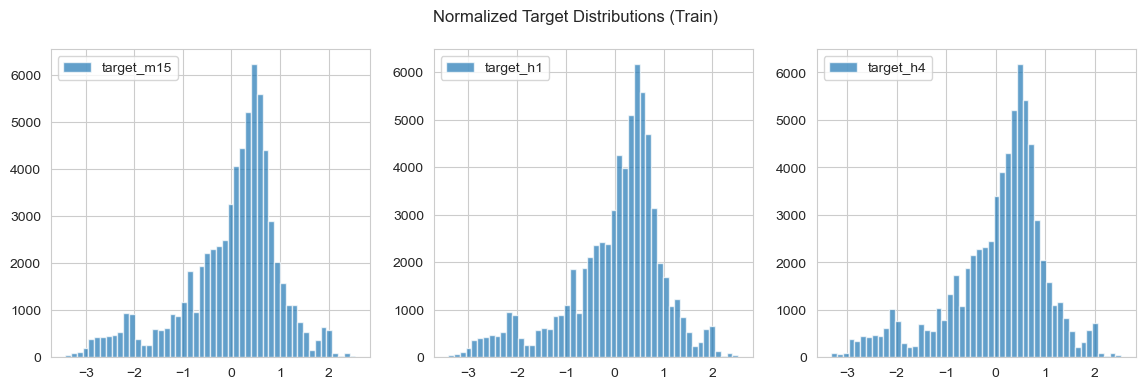

Target means (train): [0.0102 0.021  0.0426]
Target stds  (train): [0.9986 0.9973 0.9939]


In [13]:
# Display means and stds
for tf in ['m15', 'h1', 'h4']:
    print(f'{tf} feature stats:')
    for feat, m, s in zip(['open','high','low','close','volume'],
                           stats[tf]['mean'], stats[tf]['std']):
        print(f'  {feat}: mean={m:.4f}, std={s:.4f}')
    print()

# Check normalized targets on train (should be ~N(0,1))
fig, ax = plt.subplots(1, 3, figsize=(14,4))
ax[0].hist(train['target_m15'], bins=50, alpha=0.7, label='target_m15')
ax[1].hist(train['target_h1'], bins=50, alpha=0.7, label='target_h1')
ax[2].hist(train['target_h4'], bins=50, alpha=0.7, label='target_h4')
for a in ax: a.legend()
plt.suptitle('Normalized Target Distributions (Train)')
plt.show()
print('Target means (train):', train[['target_m15','target_h1','target_h4']].mean().round(4).values)
print('Target stds  (train):', train[['target_m15','target_h1','target_h4']].std().round(4).values)

## 10. Sample Timeline Visualization

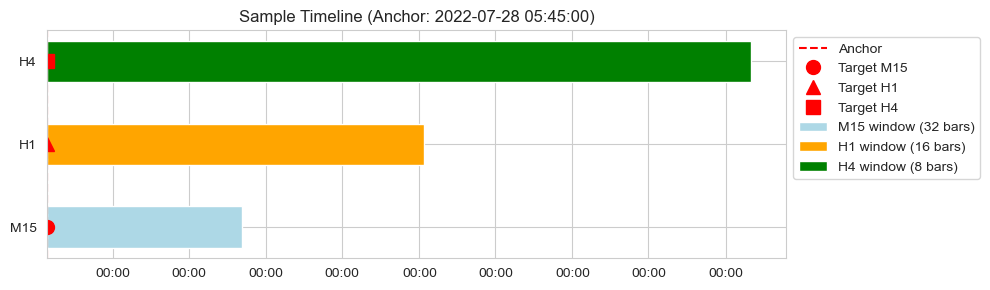

In [14]:
import matplotlib.dates as mdates
from datetime import timedelta

sample = train.iloc[200]
anchor = pd.Timestamp(sample['anchor_time'])
fig, ax = plt.subplots(figsize=(10, 3))
# M15 window span
m15_start = anchor - timedelta(minutes=15*31)
m15_end = anchor
ax.barh(1, (m15_end - m15_start).total_seconds()/60, left=m15_start,
        height=0.5, label='M15 window (32 bars)', color='lightblue')
# H1 window
h1_latest = raw_h1[raw_h1['datetime'] <= anchor].iloc[-1]['datetime']
h1_start = raw_h1[raw_h1['datetime'] <= anchor].iloc[-16]['datetime']
ax.barh(2, (h1_latest - h1_start).total_seconds()/60, left=h1_start,
        height=0.5, label='H1 window (16 bars)', color='orange')
# H4 window
h4_latest = raw_h4[raw_h4['datetime'] <= anchor].iloc[-1]['datetime']
h4_start = raw_h4[raw_h4['datetime'] <= anchor].iloc[-8]['datetime']
ax.barh(3, (h4_latest - h4_start).total_seconds()/60, left=h4_start,
        height=0.5, label='H4 window (8 bars)', color='green')

ax.axvline(anchor, color='red', linestyle='--', label='Anchor')
# Target markers
target_m15 = pd.Timestamp(sample['target_time_m15'])
target_h1  = pd.Timestamp(sample['target_time_h1'])
target_h4  = pd.Timestamp(sample['target_time_h4'])
ax.plot(target_m15, 1, 'ro', markersize=10, label='Target M15')
ax.plot(target_h1, 2, 'r^', markersize=10, label='Target H1')
ax.plot(target_h4, 3, 'rs', markersize=10, label='Target H4')

ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.set_yticks([1,2,3], ['M15', 'H1', 'H4'])
ax.legend(loc='upper left', bbox_to_anchor=(1,1))
ax.set_title(f'Sample Timeline (Anchor: {anchor})')
plt.tight_layout()
plt.show()

## 11. Final Assertions & Data Leakage Check
- No future information in training windows: already enforced by preprocessing.
- Target times must be strictly after anchor.
- All splits are chronologically disjoint.

In [16]:
# ---------------------------------------------------------
# Target time sanity checks
# ---------------------------------------------------------

for name, df in [("train", train), ("val", val), ("test", test)]:

    df["anchor_time"] = pd.to_datetime(df["anchor_time"])
    df["target_time_m15"] = pd.to_datetime(df["target_time_m15"])
    df["target_time_h1"] = pd.to_datetime(df["target_time_h1"])
    df["target_time_h4"] = pd.to_datetime(df["target_time_h4"])

    # Every target must occur after the anchor
    assert (df["target_time_m15"] > df["anchor_time"]).all(), f"{name}: invalid M15 targets"
    assert (df["target_time_h1"] > df["anchor_time"]).all(), f"{name}: invalid H1 targets"
    assert (df["target_time_h4"] > df["anchor_time"]).all(), f"{name}: invalid H4 targets"

print("✓ All targets occur after their anchors.")

# ---------------------------------------------------------
# Inspect target ordering (do not assert)
# ---------------------------------------------------------

h1_before_m15 = (train["target_time_h1"] < train["target_time_m15"]).sum()
h4_before_h1 = (train["target_time_h4"] < train["target_time_h1"]).sum()

print(f"H1 target earlier than M15 target : {h1_before_m15}")
print(f"H4 target earlier than H1 target  : {h4_before_h1}")

if h1_before_m15 > 0:
    print("\nExamples where H1 < M15:")
    display(
        train.loc[
            train["target_time_h1"] < train["target_time_m15"],
            ["anchor_time", "target_time_m15", "target_time_h1"]
        ].head()
    )

if h4_before_h1 > 0:
    print("\nExamples where H4 < H1:")
    display(
        train.loc[
            train["target_time_h4"] < train["target_time_h1"],
            ["anchor_time", "target_time_h1", "target_time_h4"]
        ].head()
    )

✓ All targets occur after their anchors.
H1 target earlier than M15 target : 1
H4 target earlier than H1 target  : 596

Examples where H1 < M15:


,anchor_time,target_time_m15,target_time_h1
33724,2023-11-29 12:30:00,2023-11-29 14:15:00,2023-11-29 14:00:00



Examples where H4 < H1:


,anchor_time,target_time_h1,target_time_h4
353,2022-07-29 20:00:00,2022-07-31 21:00:00,2022-07-31 20:00:00
354,2022-07-29 20:15:00,2022-07-31 21:00:00,2022-07-31 20:00:00
355,2022-07-29 20:30:00,2022-07-31 21:00:00,2022-07-31 20:00:00
356,2022-07-29 20:45:00,2022-07-31 21:00:00,2022-07-31 20:00:00
833,2022-08-05 20:00:00,2022-08-07 21:00:00,2022-08-07 20:00:00
